# ENGE707 Assessment 3 – Cat/Dog Facial Feature Classification

**Run order:** sections 0 → 13 top to bottom. Section 1 (data audit) scans every image once and caches the result in `runs/data_audit.csv`.

**Running an experiment:** change `RUN_NAME` and the settings in section 3, then rerun sections 3 → 12. Every run gets its own folder in `runs/` (weights, curves, metrics, submission) and a row in `runs/experiments.csv`, which section 13 uses to compare runs.

**Expected folder layout:**
```
enge707_classifier.ipynb
train_labels.csv
sample_submission.csv
train/00001.jpg ...
test/00001.jpg ...
```

## 0. Environment and reproducibility

In [1]:
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import io, json, random, time, hashlib, platform
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
import sklearn
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import matplotlib.pyplot as plt

print("python ", platform.python_version())
print("torch  ", torch.__version__, "| cuda", torch.version.cuda)
print("timm   ", timm.__version__, "| sklearn", sklearn.__version__)
print("gpu    ", torch.cuda.get_device_name(0), "| available:", torch.cuda.is_available())

torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
device = torch.device("cuda")

DATA_DIR = Path(".")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
RUNS = Path("runs")
RUNS.mkdir(exist_ok=True)
SEED = 42

def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

seed_all(SEED)

d:\ENGE707-Facial-Feature-Classification-Challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python  3.12.10
torch   2.11.0+cu128 | cuda 12.8
timm    1.0.30 | sklearn 1.9.1
gpu     NVIDIA GeForce RTX 5070 | available: True


In [2]:
!pip freeze > requirements.txt

## 1. Task 1 – Dataset exploration

### 1.1 Problem and structure
Eight-class, single-label image classification: the facial feature shown (Eye, Face, Mouth, Nose) and the species (Cat, Dog). Labels for `train/` come from `train_labels.csv`; `test/` is unlabelled and predictions go into the format of `sample_submission.csv`.

In [3]:
labels = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"image_id": str})
sample = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"image_id": str})

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def index_dir(d):
    files = [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS and p.stem.isdigit()]
    return {int(p.stem): str(p) for p in files}

train_files = index_dir(TRAIN_DIR)
test_files = index_dir(TEST_DIR)

labels["path"] = labels["image_id"].astype(int).map(train_files)
sample["path"] = sample["image_id"].astype(int).map(test_files)

if labels["path"].isna().any() or sample["path"].isna().any():
    print("example files found:", list(TRAIN_DIR.rglob("*"))[:5])
    raise FileNotFoundError("Some images were not matched to their IDs - check folder layout and file extensions above.")

print(f"train images on disk: {len(train_files)} | labelled rows: {len(labels)} | unmatched labels: {labels['path'].isna().sum()}")
print(f"test images on disk:  {len(test_files)} | submission rows: {len(sample)} | unmatched ids: {sample['path'].isna().sum()}")
print("file extensions:", pd.Series([Path(p).suffix.lower() for p in train_files.values()]).value_counts().to_dict())
print("example path:", labels["path"].iloc[0])
print("id format train csv:", labels['image_id'].head(3).tolist(), "| sample submission:", sample['image_id'].head(3).tolist())

train images on disk: 63660 | labelled rows: 63660 | unmatched labels: 0
test images on disk:  29443 | submission rows: 29443 | unmatched ids: 0
file extensions: {'.jpg': 63660}
example path: train\train\00001.jpg
id format train csv: ['00001', '00002', '00003'] | sample submission: ['1', '2', '3']


### 1.2 Class distribution and balance

          count  percent
class                   
CatEye    13884    21.81
CatFace    6942    10.90
CatMouth   6942    10.90
CatNose    6942    10.90
DogEye    11580    18.19
DogFace    5790     9.10
DogMouth   5790     9.10
DogNose    5790     9.10
imbalance ratio (largest / smallest): 2.40


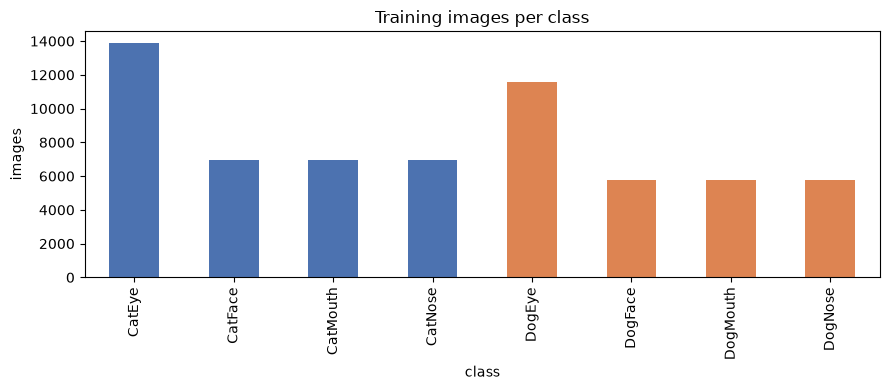

In [4]:
CLASSES = sorted(labels["class"].unique())
counts = labels["class"].value_counts().reindex(CLASSES)
dist = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(2)})
print(dist)
print(f"imbalance ratio (largest / smallest): {counts.max() / counts.min():.2f}")

ax = counts.plot.bar(figsize=(9, 4), color=["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in CLASSES])
ax.set_ylabel("images")
ax.set_title("Training images per class")
plt.tight_layout()
plt.savefig(RUNS / "class_distribution.png", dpi=150)
plt.show()

### 1.3 Representative samples

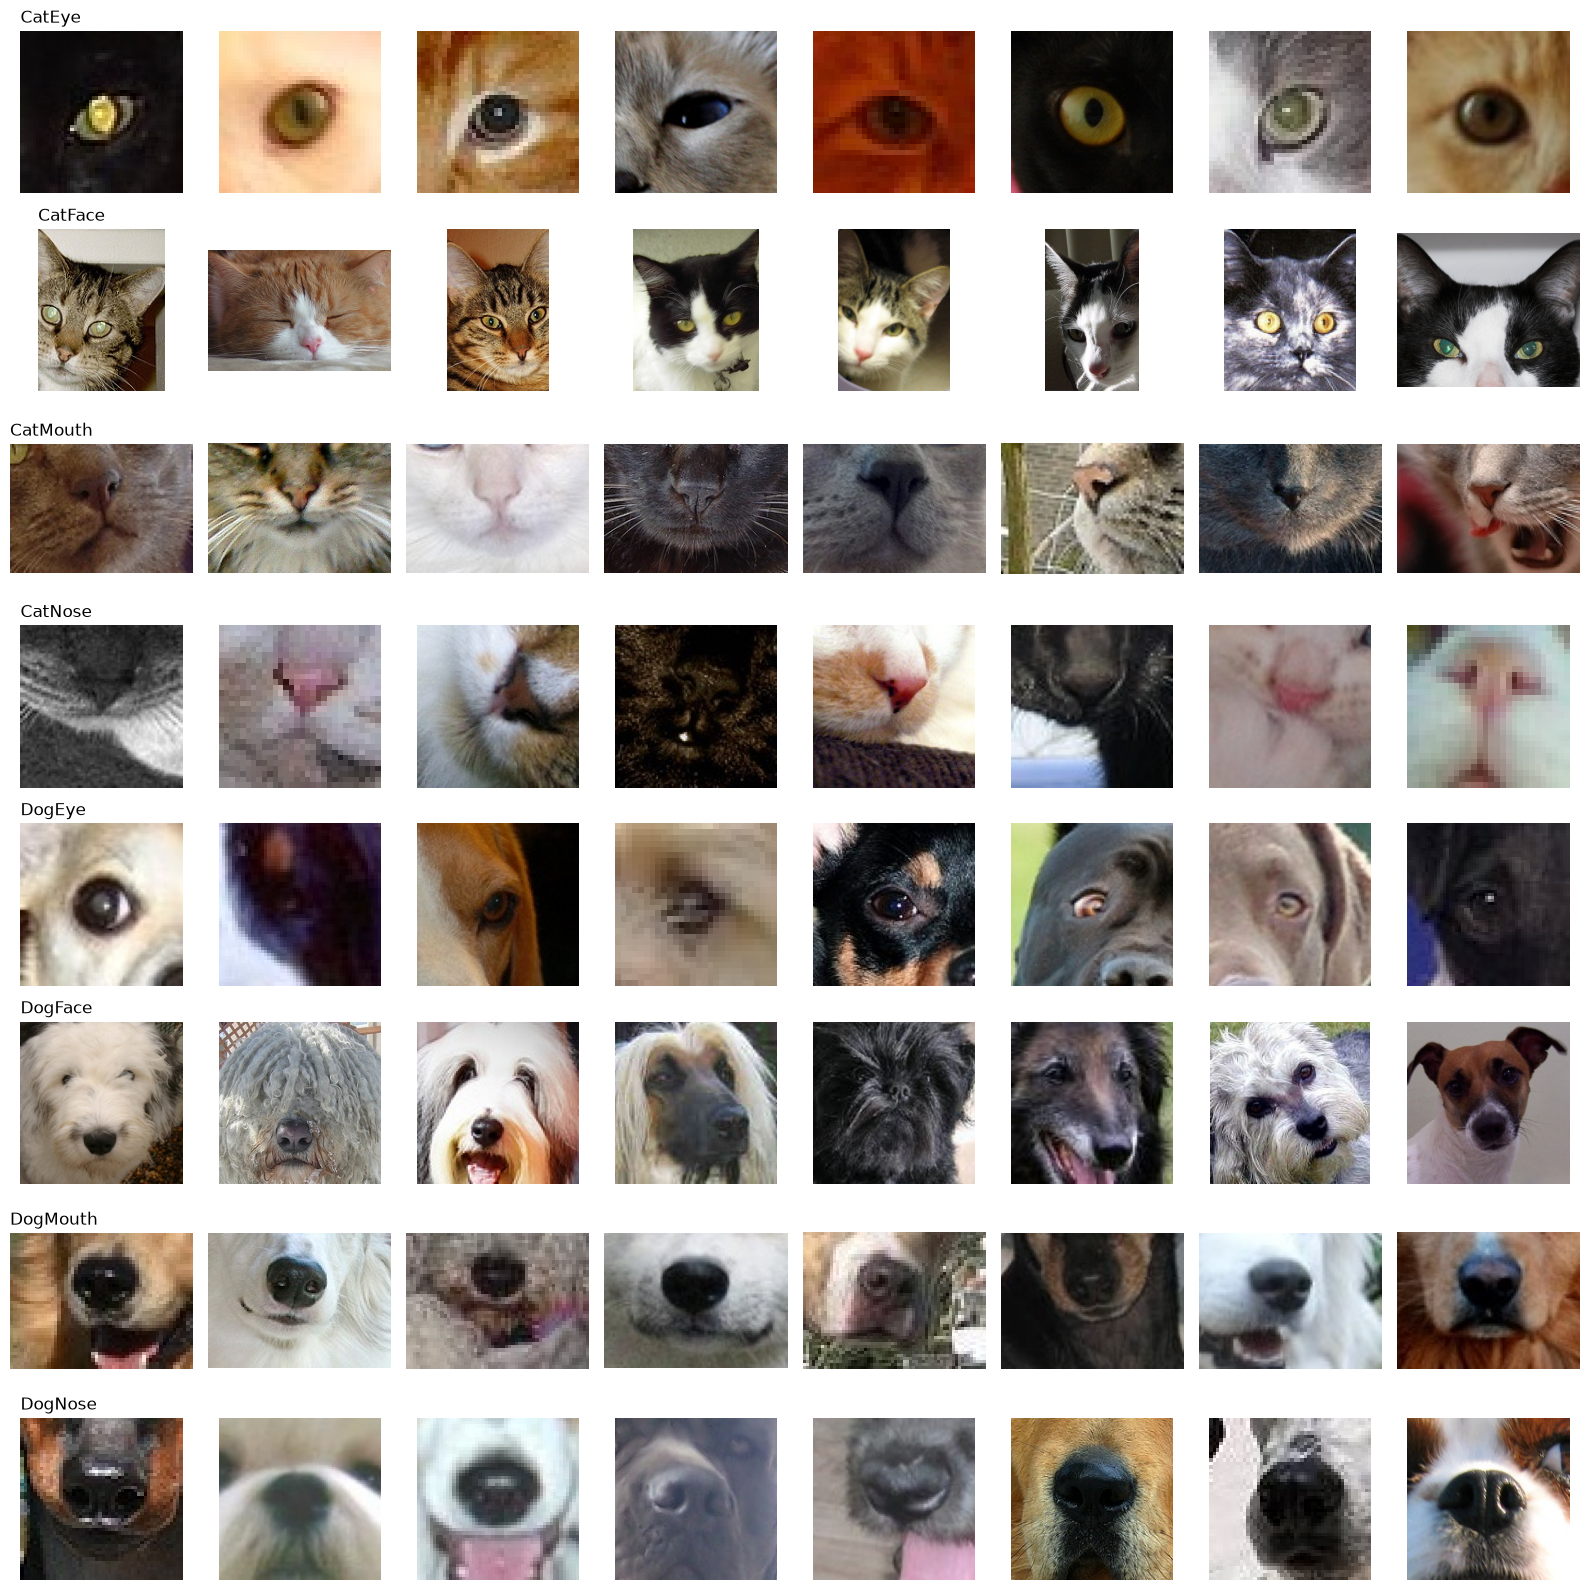

In [5]:
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(16, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    for k, p in enumerate(labels[labels["class"] == c]["path"].sample(8, random_state=SEED)):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left")
plt.tight_layout()
plt.savefig(RUNS / "samples.png", dpi=120)
plt.show()

### 1.4 Data quality audit
For every train and test image: whether it opens (corruption), size, colour mode, MD5 of the file bytes (exact duplicates), a 64-bit difference hash (near-duplicates that survive resizing/re-encoding), and the variance of the Laplacian on a 128×128 greyscale copy (low = blurry).

In [6]:
def audit(path):
    r = {"path": path, "error": ""}
    try:
        b = Path(path).read_bytes()
        r["md5"] = hashlib.md5(b).hexdigest()
        with Image.open(io.BytesIO(b)) as im:
            r["format"], r["mode"] = im.format, im.mode
            r["width"], r["height"] = im.size
            g = im.convert("L")
        d = np.asarray(g.resize((9, 8), Image.BILINEAR), dtype=np.int16)
        bits = (d[:, 1:] > d[:, :-1]).flatten()
        r["dhash"] = format(int("".join("1" if v else "0" for v in bits), 2), "016x")
        a = np.asarray(g.resize((128, 128), Image.BILINEAR), dtype=np.float32)
        lap = a[1:-1, :-2] + a[1:-1, 2:] + a[:-2, 1:-1] + a[2:, 1:-1] - 4 * a[1:-1, 1:-1]
        r["blur"] = float(lap.var())
    except Exception as e:
        r["error"] = repr(e)
    return r

AUDIT_CSV = RUNS / "data_audit.csv"
if AUDIT_CSV.exists():
    audit_df = pd.read_csv(AUDIT_CSV, dtype={"dhash": str, "md5": str}, keep_default_na=False)
else:
    t = time.time()
    jobs = [("train", p) for p in labels["path"].dropna()] + [("test", p) for p in sample["path"].dropna()]
    with ThreadPoolExecutor(16) as ex:
        rows = list(ex.map(lambda j: {"split": j[0], **audit(j[1])}, jobs))
    audit_df = pd.DataFrame(rows)
    audit_df.to_csv(AUDIT_CSV, index=False)
    print(f"audited {len(audit_df)} images in {time.time() - t:.0f}s")

labels = labels.merge(audit_df[audit_df["split"] == "train"].drop(columns="split"), on="path", how="left")
test_audit = audit_df[audit_df["split"] == "test"]
print("corrupted / unreadable:", (audit_df["error"] != "").groupby(audit_df["split"]).sum().to_dict())

corrupted / unreadable: {'test': 0, 'train': 0}


colour modes: {'RGB': 93103}
formats:      {'JPEG': 93103}

image size summary:
split            test    train
width  count  29443.0  63660.0
       mean     113.5    113.1
       std      100.7     98.5
       min        8.0      4.0
       25%       53.0     54.0
       50%       82.0     84.0
       75%      140.0    138.0
       max     1832.0   2219.0
height count  29443.0  63660.0
       mean     109.7    109.7
       std      103.7    101.9
       min        9.0      4.0
       25%       50.0     50.0
       50%       80.0     80.0
       75%      128.0    130.0
       max     1978.0   2219.0

most common sizes:
40x40    1565
50x50    1295
60x60    1213
48x48    1198
30x30    1123
38x38    1114
42x42    1113
44x44    1099
Name: count, dtype: int64


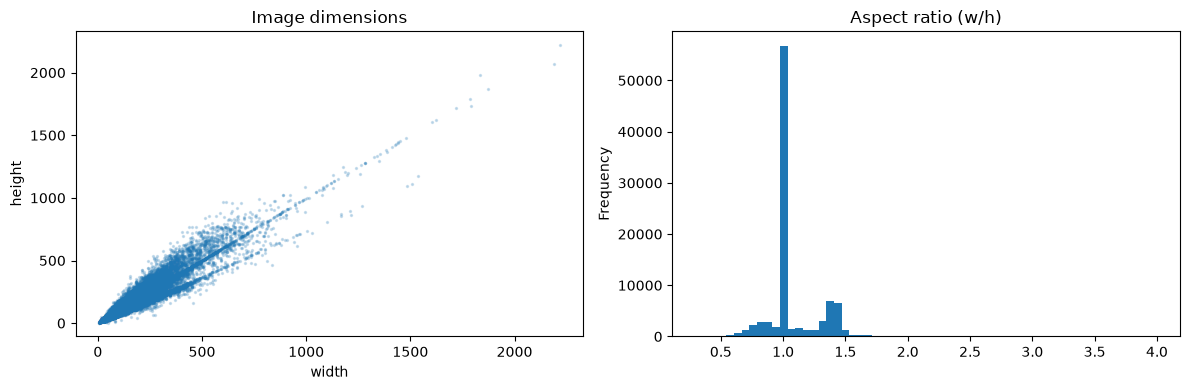


blur score (Laplacian variance) by class, median:
class
CatEye      102.7
CatFace     602.1
CatMouth    208.2
CatNose      65.3
DogEye       43.2
DogFace     396.2
DogMouth    150.7
DogNose      49.4
Name: blur, dtype: float64


In [7]:
ok = audit_df[audit_df["error"] == ""].copy()
ok["width"] = ok["width"].astype(int)
ok["height"] = ok["height"].astype(int)
print("colour modes:", ok["mode"].value_counts().to_dict())
print("formats:     ", ok["format"].value_counts().to_dict())
print("\nimage size summary:")
print(ok.groupby("split")[["width", "height"]].describe().T.round(1))
print("\nmost common sizes:")
print((ok["width"].astype(str) + "x" + ok["height"].astype(str)).value_counts().head(8))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(ok["width"], ok["height"], s=2, alpha=0.2)
ax[0].set_xlabel("width")
ax[0].set_ylabel("height")
ax[0].set_title("Image dimensions")
(ok["width"] / ok["height"]).clip(0.25, 4).plot.hist(bins=60, ax=ax[1])
ax[1].set_title("Aspect ratio (w/h)")
plt.tight_layout()
plt.savefig(RUNS / "image_sizes.png", dpi=150)
plt.show()

lab_ok = labels[labels["error"] == ""].copy()
lab_ok["blur"] = lab_ok["blur"].astype(float)
print("\nblur score (Laplacian variance) by class, median:")
print(lab_ok.groupby("class")["blur"].median().round(1))

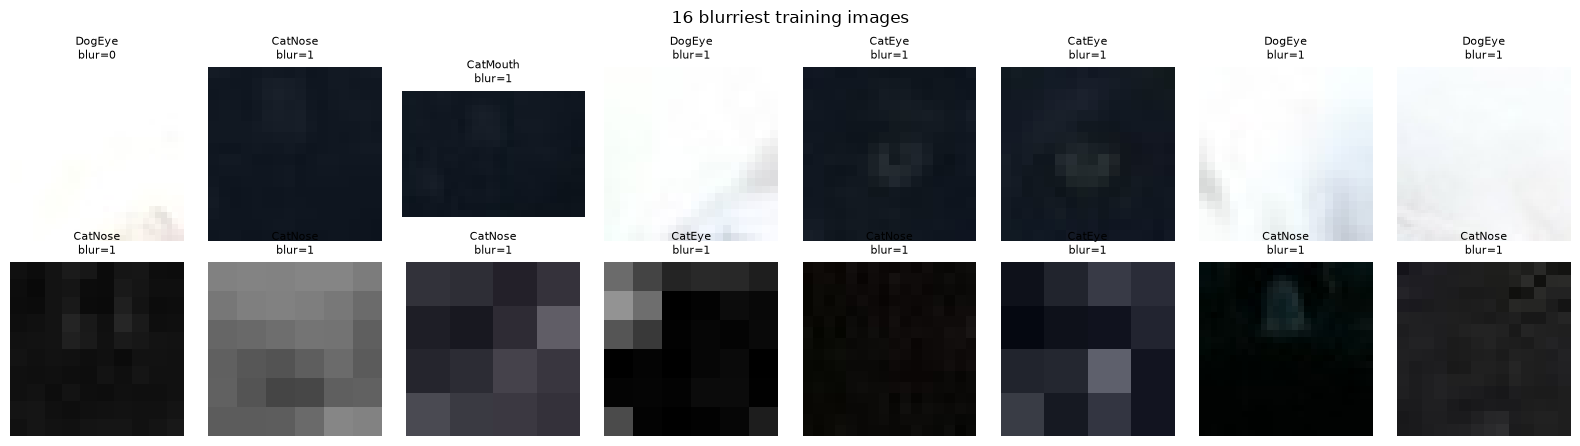

In [8]:
blurry = lab_ok.nsmallest(16, "blur")
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for a, (_, r) in zip(axes.flat, blurry.iterrows()):
    a.imshow(Image.open(r["path"]).convert("RGB"))
    a.set_title(f"{r['class']}\nblur={r['blur']:.0f}", fontsize=8)
    a.axis("off")
plt.suptitle("16 blurriest training images")
plt.tight_layout()
plt.savefig(RUNS / "blurriest.png", dpi=120)
plt.show()

In [9]:
def dup_report(df, key, name):
    g = df.groupby(key)
    sizes = g.size()
    dup_groups = sizes[sizes > 1]
    conflict = g["class"].nunique()
    conflict = conflict[conflict > 1]
    print(f"{name}: {len(dup_groups)} groups covering {dup_groups.sum()} images | groups with conflicting labels: {len(conflict)} ({sizes[conflict.index].sum()} images)")
    return conflict.index

exact_conflicts = dup_report(lab_ok, "md5", "exact duplicates (md5) in train")
near_conflicts = dup_report(lab_ok, "dhash", "near duplicates (dhash) in train")

print("train/test overlap  exact:", test_audit["md5"].isin(lab_ok["md5"]).sum(),
      "| near:", test_audit["dhash"].isin(lab_ok["dhash"]).sum())

exact duplicates (md5) in train: 15 groups covering 30 images | groups with conflicting labels: 0 (0 images)
near duplicates (dhash) in train: 47 groups covering 94 images | groups with conflicting labels: 0 (0 images)
train/test overlap  exact: 0 | near: 3


In [10]:
ex = lab_ok[lab_ok["dhash"].isin(near_conflicts)].sort_values("dhash")
groups = ex["dhash"].unique()[:6]
if len(groups):
    fig, axes = plt.subplots(len(groups), 4, figsize=(8, 2.2 * len(groups)), squeeze=False)
    for r, h in enumerate(groups):
        rows = ex[ex["dhash"] == h].head(4)
        for k in range(4):
            axes[r, k].axis("off")
        for k, (_, row) in enumerate(rows.iterrows()):
            axes[r, k].imshow(Image.open(row["path"]).convert("RGB"))
            axes[r, k].set_title(f"{row['image_id']} {row['class']}", fontsize=8)
    plt.suptitle("Near-duplicates with conflicting labels")
    plt.tight_layout()
    plt.savefig(RUNS / "label_conflicts.png", dpi=120)
    plt.show()

### 1.5 Cleaning decision
Unreadable files and **exact** duplicates whose copies carry different labels are removed (their label is unknowable). Near-duplicate conflicts are only flagged, since an identical hash can come from genuinely different but similar-looking crops.

`SUSPECT_FILE` can point at a `suspect_labels.csv` produced by section 9 of an earlier 5-fold run to also remove likely mislabelled images. Leave it as `None` for the first runs.

In [11]:
SUSPECT_FILE = None

before = len(labels)
data = labels[(labels["error"] == "") & (~labels["md5"].isin(exact_conflicts))].reset_index(drop=True)
print(f"removed {before - len(data)} unreadable/conflicting images")

if SUSPECT_FILE is not None:
    sus = pd.read_csv(SUSPECT_FILE, dtype={"image_id": str})
    n = len(data)
    data = data[~data["image_id"].isin(sus["image_id"])].reset_index(drop=True)
    print(f"removed {n - len(data)} suspected label errors listed in {SUSPECT_FILE}")
print(f"{len(data)} images remain for training/validation")

removed 0 unreadable/conflicting images
63660 images remain for training/validation


## 2. Task 2 – Preprocessing pipeline

- **Label encoding:** class names sorted alphabetically → integers 0–7; the same list maps predictions back to names.
- **K-fold split:** every image is assigned to one of 5 folds with `StratifiedGroupKFold`: **stratified** (each fold keeps the class proportions) and **grouped by near-duplicate hash** (near-identical images always land in the same fold, preventing leakage). Training fold *k* means validating on fold *k* and training on the other four. Running all 5 folds gives an out-of-fold (OOF) prediction for every training image, a more reliable score than one split, and 5 models to average.
- **Resize / normalise / augment:** defined in section 4 from the model's pretraining config (ImageNet mean/std normalisation, bicubic resize). Augmentation only on training data; validation and test share one deterministic transform.

In [12]:
cls2idx = {c: i for i, c in enumerate(CLASSES)}
data["y"] = data["class"].map(cls2idx)
print(cls2idx)

N_FOLDS = 5
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
data["fold"] = -1
for k, (_, va_idx) in enumerate(sgkf.split(data, data["y"], groups=data["dhash"])):
    data.loc[va_idx, "fold"] = k

leak = [len(set(data.loc[data["fold"] == k, "dhash"]) & set(data.loc[data["fold"] != k, "dhash"])) for k in range(N_FOLDS)]
print("near-duplicate groups shared between each fold and the rest:", leak)
print("images per fold:", data["fold"].value_counts().sort_index().tolist())
(pd.crosstab(data["class"], data["fold"], normalize="columns") * 100).round(2)

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
near-duplicate groups shared between each fold and the rest: [0, 0, 0, 0, 0]
images per fold: [12732, 12733, 12732, 12732, 12731]


fold,0,1,2,3,4
class,,,,,
CatEye,21.81,21.81,21.81,21.80,21.81
CatFace,10.90,10.91,10.90,10.91,10.90
CatMouth,10.90,10.91,10.91,10.90,10.90
CatNose,10.91,10.90,10.90,10.91,10.90
DogEye,18.19,18.19,18.19,18.19,18.19
DogFace,9.10,9.09,9.10,9.10,9.10
DogMouth,9.10,9.09,9.10,9.10,9.10
DogNose,9.10,9.09,9.10,9.10,9.10


Dataset class written to a module so DataLoader worker processes can import it (needed on Windows with `num_workers > 0`).

In [13]:
%%writefile data.py
from PIL import Image
from torch.utils.data import Dataset

class ImgDS(Dataset):
    def __init__(self, paths, ys, tf):
        self.paths = list(paths)
        self.ys = ys
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        y = self.ys[i] if self.ys is not None else -1
        return self.tf(img), y

Overwriting data.py


## 3. Experiment config
Change these per experiment. Use `FOLDS_TO_RUN = [0]` for quick comparisons (one model, validated on fold 0), and `[0, 1, 2, 3, 4]` for the final run (5 models, full OOF evaluation, ~5× the time).

| RUN_NAME | MODEL_NAME | Notes |
|---|---|---|
| resnet18_scratch | resnet18 | `PRETRAINED=False`, `AUGMENT="basic"` – baseline without transfer learning |
| convnext_t_noaug | convnext_tiny.fb_in22k_ft_in1k | `AUGMENT="none"` – shows effect of augmentation |
| convnext_t | convnext_tiny.fb_in22k_ft_in1k | main CNN |
| convnext_t_mix | convnext_tiny.fb_in22k_ft_in1k | `MIX_PROB=0.5` – Mixup/CutMix |
| convnextv2_t | convnextv2_tiny.fcmae_ft_in22k_in1k | stronger pretraining |
| convnext_s | convnext_small.fb_in22k_ft_in1k | bigger CNN, `BATCH_SIZE=64` if memory runs out |
| vit_s | vit_small_patch16_224.augreg_in21k_ft_in1k | Vision Transformer, `LR=1e-4`, keep `FT_EPOCHS=0` (fixed 224 input) |

**Options:**
- `EMA_DECAY` – evaluate/save an exponential moving average of the weights.
- `MIX_PROB` – chance each batch gets Mixup or CutMix (0 = off).
- `FT_EPOCHS` – extra fine-tuning epochs at `FT_IMG_SIZE` after the main stage (0 = off). Only useful if most images are larger than `IMG_SIZE`.
- `TTA` – average predictions with a horizontally flipped copy at evaluation.
- `CROP_SCALE` – smallest/largest fraction of the image kept by the random crop. Raise the lower bound (e.g. `(0.85, 1.0)`) if small-detail classes such as noses and mouths suffer.
- `RE_PROB` – chance of random erasing (blanking a patch). Lower it (e.g. `0.0`) if it hides the distinguishing detail.
- `CLASS_WEIGHTING` – weight the loss by inverse class frequency so the smaller classes count more. Not applied when Mixup is on.

In [14]:
RUN_NAME = "convnext_t"
MODEL_NAME = "convnext_tiny.fb_in22k_ft_in1k"
PRETRAINED = True
AUGMENT = "strong"
FOLDS_TO_RUN = [0]

IMG_SIZE = 224
BATCH_SIZE = 128
EPOCHS = 15
PATIENCE = 6
LR = 4e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 1
LABEL_SMOOTHING = 0.1
DROP_RATE = 0.2
DROP_PATH_RATE = 0.1
EMA_DECAY = 0.999

CROP_SCALE = (0.6, 1.0)
RE_PROB = 0.2
CLASS_WEIGHTING = False

MIX_PROB = 0.0
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0

FT_EPOCHS = 0
FT_IMG_SIZE = 288
FT_LR = 5e-5

TTA = True
NUM_WORKERS = 8

CFG = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (str, int, float, bool, list, tuple))}
OUT_DIR = RUNS / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(OUT_DIR / "config.json", "w"), indent=2)
CFG

{'SEED': 42,
 'CLASSES': ['CatEye',
  'CatFace',
  'CatMouth',
  'CatNose',
  'DogEye',
  'DogFace',
  'DogMouth',
  'DogNose'],
 'N_FOLDS': 5,
 'RUN_NAME': 'convnext_t',
 'MODEL_NAME': 'convnext_tiny.fb_in22k_ft_in1k',
 'PRETRAINED': True,
 'AUGMENT': 'strong',
 'FOLDS_TO_RUN': [0],
 'IMG_SIZE': 224,
 'BATCH_SIZE': 128,
 'EPOCHS': 15,
 'PATIENCE': 6,
 'LR': 0.0004,
 'WEIGHT_DECAY': 0.05,
 'WARMUP_EPOCHS': 1,
 'LABEL_SMOOTHING': 0.1,
 'DROP_RATE': 0.2,
 'DROP_PATH_RATE': 0.1,
 'EMA_DECAY': 0.999,
 'CROP_SCALE': (0.6, 1.0),
 'RE_PROB': 0.2,
 'CLASS_WEIGHTING': False,
 'MIX_PROB': 0.0,
 'MIXUP_ALPHA': 0.2,
 'CUTMIX_ALPHA': 1.0,
 'FT_EPOCHS': 0,
 'FT_IMG_SIZE': 288,
 'FT_LR': 5e-05,
 'TTA': True,
 'NUM_WORKERS': 8}

## 4. Task 3 – Model and transforms

In [15]:
from data import ImgDS
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy
from timm.utils import ModelEmaV3

def make_model():
    return timm.create_model(MODEL_NAME, pretrained=PRETRAINED, num_classes=len(CLASSES),
                             drop_rate=DROP_RATE, drop_path_rate=DROP_PATH_RATE)

def make_transforms(net, size, augment):
    dcfg = timm.data.resolve_data_config({}, model=net)
    dcfg["input_size"] = (3, size, size)
    dcfg["crop_pct"] = 1.0
    val_tf = timm.data.create_transform(**dcfg, is_training=False)
    if augment == "strong":
        train_tf = timm.data.create_transform(**dcfg, is_training=True, hflip=0.5, scale=CROP_SCALE,
                                              auto_augment="rand-m7-mstd0.5", re_prob=RE_PROB)
    elif augment == "basic":
        train_tf = timm.data.create_transform(**dcfg, is_training=True, hflip=0.5, scale=(0.8, 1.0), color_jitter=0.2)
    else:
        train_tf = val_tf
    return train_tf, val_tf, dcfg

def make_mixup(prob):
    return Mixup(mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, prob=prob, switch_prob=0.5,
                 label_smoothing=LABEL_SMOOTHING, num_classes=len(CLASSES))

probe = make_model()
n_params = sum(p.numel() for p in probe.parameters())
train_tf, val_tf, dcfg = make_transforms(probe, IMG_SIZE, AUGMENT)
print(f"{MODEL_NAME}: {n_params / 1e6:.1f}M parameters")
print("output layer:", probe.get_classifier())
print("output: logits for", len(CLASSES), "classes -> softmax at inference, cross-entropy during training")
print("input pipeline:", dcfg)
print("\ntrain transform:\n", train_tf)
print("\nval/test transform:\n", val_tf)
del probe

convnext_tiny.fb_in22k_ft_in1k: 27.8M parameters
output layer: Linear(in_features=768, out_features=8, bias=True)
output: logits for 8 classes -> softmax at inference, cross-entropy during training
input pipeline: {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 1.0, 'crop_mode': 'center'}

train transform:
 Compose(
    RandomResizedCropAndInterpolation(size=(224, 224), scale=(0.6, 1.0), ratio=(0.75, 1.3333), interpolation=bicubic)
    RandomHorizontalFlip(p=0.5)
    RandAugment(n=2, ops=
	AugmentOp(name=AutoContrast, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Equalize, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Invert, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Rotate, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Posterize, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Solarize, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=SolarizeAdd, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Color, p=0.5, m=7, mstd=0.5)
	AugmentOp(name=Contrast, p=0.5, m=7, 

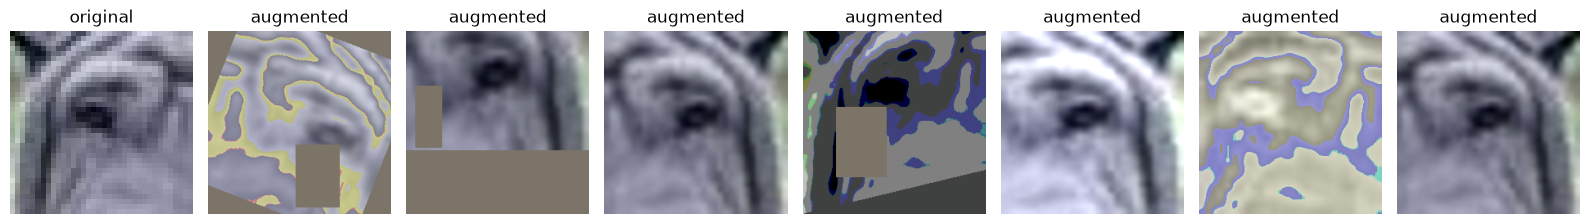

In [16]:
mean = torch.tensor(dcfg["mean"]).view(3, 1, 1)
std = torch.tensor(dcfg["std"]).view(3, 1, 1)
show = lambda t: (t * std + mean).clamp(0, 1).permute(1, 2, 0)

img = Image.open(data["path"].iloc[0]).convert("RGB")
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(img)
axes[0].set_title("original")
for a in axes[1:]:
    a.imshow(show(train_tf(img)))
    a.set_title("augmented")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "augmentations.png", dpi=120)
plt.show()

if MIX_PROB > 0:
    rows = data.sample(8, random_state=SEED)
    xb = torch.stack([val_tf(Image.open(p).convert("RGB")) for p in rows["path"]])
    xm, ym = make_mixup(1.0)(xb, torch.tensor(rows["y"].values))
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
    for a, x, t in zip(axes, xm, ym):
        top = t.topk(2)
        a.imshow(show(x))
        a.set_title(f"{CLASSES[top.indices[0]]} {top.values[0]:.2f}\n{CLASSES[top.indices[1]]} {top.values[1]:.2f}", fontsize=8)
        a.axis("off")
    plt.suptitle("Mixup / CutMix examples with soft labels")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "mixup.png", dpi=120)
    plt.show()

## 5. Task 4 – Training
Per fold:
1. **Main stage** at `IMG_SIZE`: AdamW, linear warm-up then cosine learning-rate decay, optional Mixup/CutMix, label smoothing, dropout and stochastic depth.
2. **EMA:** after every weight update a smoothed copy of the weights is updated; that copy is what gets validated and saved.
3. **Early stopping** on validation accuracy with `PATIENCE`; the best EMA weights are checkpointed.
4. **Optional fine-tune stage** (`FT_EPOCHS > 0`) at `FT_IMG_SIZE` with a small learning rate, lighter augmentation and no Mixup, starting from the best weights.
5. The best checkpoint predicts its validation fold and the test set (with TTA).

Mixed precision (bf16) and channels-last memory layout keep the RTX 5070 busy. Training accuracy is measured on augmented/mixed images with dropout active, so it can sit below validation accuracy without meaning underfitting.

In [17]:
def loader(df, tf, train, labelled=True):
    ys = df["y"].tolist() if labelled else None
    return DataLoader(ImgDS(df["path"], ys, tf), batch_size=BATCH_SIZE if train else BATCH_SIZE * 2,
                      shuffle=train, drop_last=train, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=True)

def cosine_sched(opt, steps, warm):
    def f(s):
        if s < warm:
            return (s + 1) / warm
        return 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, steps - warm)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_epoch(net, ema, dl, opt, sched, crit, mix):
    net.train()
    tot, correct, n = 0.0, 0, 0
    for x, y in dl:
        x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(device, non_blocking=True)
        target = y
        if mix is not None:
            x, target = mix(x, y)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out = net(x)
            loss = crit(out, target)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        ema.update(net)
        tot += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

@torch.no_grad()
def predict(net, dl, tta=None):
    tta = TTA if tta is None else tta
    net.eval()
    probs = []
    for x, _ in dl:
        x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            p = net(x).float().softmax(1)
            if tta:
                p = (p + net(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        probs.append(p.cpu())
    return torch.cat(probs).numpy()

def class_weights(df):
    if not CLASS_WEIGHTING:
        return None
    counts = np.bincount(df["y"], minlength=len(CLASSES))
    w = counts.sum() / (len(CLASSES) * counts)
    return torch.tensor(w, dtype=torch.float32, device=device)

def val_metrics(probs, y):
    loss = float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1)).mean())
    return loss, float((probs.argmax(1) == y).mean())

In [18]:
def train_fold(k):
    seed_all(SEED + k)
    tr = data[data["fold"] != k].reset_index(drop=True)
    va = data[data["fold"] == k].reset_index(drop=True)
    y_va = va["y"].to_numpy()
    ckpt = OUT_DIR / f"best_f{k}.pt"
    model = make_model().to(device, memory_format=torch.channels_last)
    hist = []
    st = {"best": 0.0, "best_ep": 0, "best_size": IMG_SIZE}

    def run_stage(stage, n_epochs, size, augment, lr, warm, mix, crit, ema):
        train_tf, val_tf, _ = make_transforms(model, size, augment)
        tr_dl, va_dl = loader(tr, train_tf, True), loader(va, val_tf, False)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
        sched = cosine_sched(opt, n_epochs * len(tr_dl), warm * len(tr_dl))
        wait = 0
        for e in range(1, n_epochs + 1):
            t = time.time()
            lr_now = opt.param_groups[0]["lr"]
            tl, ta = train_epoch(model, ema, tr_dl, opt, sched, crit, mix)
            vl, vacc = val_metrics(predict(ema.module, va_dl, tta=False), y_va)
            hist.append(dict(fold=k, epoch=len(hist) + 1, stage=stage, img_size=size, lr=lr_now,
                             train_loss=tl, train_acc=ta, val_loss=vl, val_acc=vacc))
            if vacc > st["best"]:
                st.update(best=vacc, best_ep=len(hist), best_size=size)
                torch.save(ema.module.state_dict(), ckpt)
                wait = 0
            else:
                wait += 1
            print(f"f{k} {stage:4s} {len(hist):02d} | lr {lr_now:.2e} | train {tl:.4f} {ta:.4f} | "
                  f"val(ema) {vl:.4f} {vacc:.4f} | best {st['best']:.4f}@{st['best_ep']} | {time.time() - t:.0f}s")
            if wait >= PATIENCE:
                print(f"early stopping: no improvement for {PATIENCE} epochs")
                break

    if MIX_PROB > 0:
        mix, crit = make_mixup(MIX_PROB), SoftTargetCrossEntropy()
    else:
        mix, crit = None, nn.CrossEntropyLoss(weight=class_weights(tr), label_smoothing=LABEL_SMOOTHING)
    run_stage("main", EPOCHS, IMG_SIZE, AUGMENT, LR, WARMUP_EPOCHS, mix, crit, ModelEmaV3(model, decay=EMA_DECAY))

    if FT_EPOCHS > 0:
        model.load_state_dict(torch.load(ckpt))
        ft_aug = "basic" if AUGMENT == "strong" else AUGMENT
        run_stage("ft", FT_EPOCHS, FT_IMG_SIZE, ft_aug, FT_LR, 0, None,
                  nn.CrossEntropyLoss(weight=class_weights(tr), label_smoothing=LABEL_SMOOTHING),
                  ModelEmaV3(model, decay=EMA_DECAY))

    model.load_state_dict(torch.load(ckpt))
    _, val_tf, _ = make_transforms(model, st["best_size"], "none")
    va_probs = predict(model, loader(va, val_tf, False))
    te_probs = predict(model, loader(sample, val_tf, False, labelled=False))
    vl, vacc = val_metrics(va_probs, y_va)
    print(f"fold {k}: best epoch {st['best_ep']} at {st['best_size']}px | val acc {vacc:.4f} | val loss {vl:.4f} (TTA={TTA})")

    del model
    torch.cuda.empty_cache()
    return dict(image_id=va["image_id"].values, val_probs=va_probs, test_probs=te_probs,
                hist=pd.DataFrame(hist), best_ep=st["best_ep"], best_size=st["best_size"], val_acc=vacc, val_loss=vl)

In [19]:
results = {}
t0 = time.time()
for k in FOLDS_TO_RUN:
    print(f"========== fold {k} ==========")
    results[k] = train_fold(k)
train_time = (time.time() - t0) / 60
print(f"training time {train_time:.1f} min")

oof = pd.concat([pd.DataFrame(r["val_probs"], columns=CLASSES).assign(image_id=r["image_id"], fold=k)
                 for k, r in results.items()], ignore_index=True)
oof = oof.merge(data[["image_id", "class", "y", "path", "blur"]], on="image_id")
oof.to_csv(OUT_DIR / "oof.csv", index=False)

test_probs = np.mean([r["test_probs"] for r in results.values()], axis=0)
np.save(OUT_DIR / "test_probs.npy", test_probs)

hist = pd.concat([r["hist"] for r in results.values()], ignore_index=True)
hist.to_csv(OUT_DIR / "history.csv", index=False)

fold_table = pd.DataFrame({k: {"val_acc": r["val_acc"], "val_loss": r["val_loss"], "best_epoch": r["best_ep"],
                               "best_size": r["best_size"]} for k, r in results.items()}).T
fold_table

========== fold 0 ==========
f0 main 01 | lr 1.01e-06 | train 0.8716 0.8200 | val(ema) 0.8076 0.8153 | best 0.8153@1 | 163s
f0 main 02 | lr 4.00e-04 | train 0.6019 0.9391 | val(ema) 0.2974 0.9169 | best 0.9169@2 | 94s
f0 main 03 | lr 3.95e-04 | train 0.5731 0.9523 | val(ema) 0.2210 0.9426 | best 0.9426@3 | 101s
f0 main 04 | lr 3.80e-04 | train 0.5592 0.9577 | val(ema) 0.1987 0.9489 | best 0.9489@4 | 101s
f0 main 05 | lr 3.56e-04 | train 0.5485 0.9630 | val(ema) 0.1896 0.9526 | best 0.9526@5 | 101s
f0 main 06 | lr 3.25e-04 | train 0.5434 0.9649 | val(ema) 0.1841 0.9547 | best 0.9547@6 | 101s
f0 main 07 | lr 2.87e-04 | train 0.5331 0.9701 | val(ema) 0.1816 0.9555 | best 0.9555@7 | 102s
f0 main 08 | lr 2.45e-04 | train 0.5261 0.9726 | val(ema) 0.1810 0.9566 | best 0.9566@8 | 101s
f0 main 09 | lr 2.00e-04 | train 0.5214 0.9741 | val(ema) 0.1822 0.9570 | best 0.9570@9 | 101s
f0 main 10 | lr 1.55e-04 | train 0.5172 0.9769 | val(ema) 0.1826 0.9564 | best 0.9570@9 | 105s
f0 main 11 | lr 1.13e-

,val_acc,val_loss,best_epoch,best_size
0,0.957509,0.185597,14.0,224.0


## 6. Learning curves

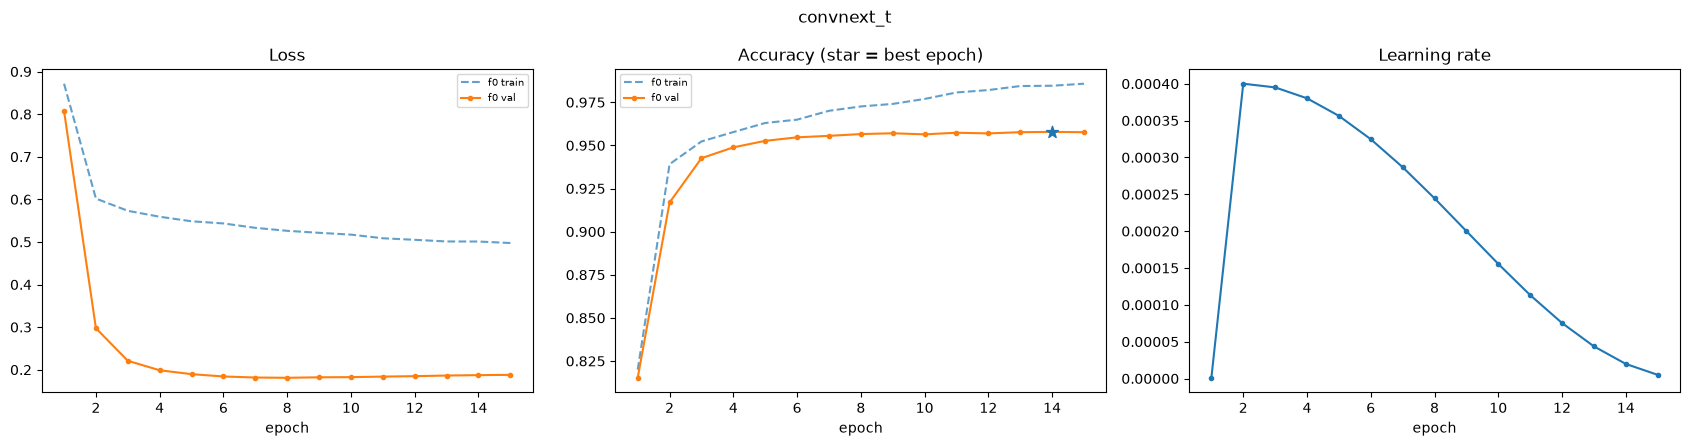

fold 0: best val acc 0.9578 at epoch 14 of 15 | final train acc 0.9858 vs val 0.9577 (gap +0.0281) | val loss min at epoch 8


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, r in results.items():
    h = r["hist"]
    ax[0].plot(h["epoch"], h["train_loss"], "--", alpha=0.7, label=f"f{k} train")
    ax[0].plot(h["epoch"], h["val_loss"], "o-", ms=3, label=f"f{k} val")
    ax[1].plot(h["epoch"], h["train_acc"], "--", alpha=0.7, label=f"f{k} train")
    ax[1].plot(h["epoch"], h["val_acc"], "o-", ms=3, label=f"f{k} val")
    ax[2].plot(h["epoch"], h["lr"], "o-", ms=3, label=f"f{k}")
    ax[1].scatter([r["best_ep"]], [h.loc[h["epoch"] == r["best_ep"], "val_acc"]], s=80, marker="*", zorder=5)
    ft = h.loc[h["stage"] == "ft", "epoch"]
    if len(ft):
        for a in ax:
            a.axvline(ft.min() - 0.5, color="grey", ls=":", lw=1)
ax[0].set_title("Loss")
ax[1].set_title("Accuracy (star = best epoch)")
ax[2].set_title("Learning rate")
for a in ax:
    a.set_xlabel("epoch")
ax[0].legend(fontsize=7)
ax[1].legend(fontsize=7)
plt.suptitle(RUN_NAME)
plt.tight_layout()
plt.savefig(OUT_DIR / "curves.png", dpi=150)
plt.show()

for k, r in results.items():
    h = r["hist"]
    last = h.iloc[-1]
    print(f"fold {k}: best val acc {h.val_acc.max():.4f} at epoch {r['best_ep']} of {len(h)} | "
          f"final train acc {last.train_acc:.4f} vs val {last.val_acc:.4f} (gap {last.train_acc - last.val_acc:+.4f}) | "
          f"val loss min at epoch {int(h.loc[h.val_loss.idxmin(), 'epoch'])}")

## 7. Task 5 – Validation evaluation
Computed on the out-of-fold predictions: each image is scored by the model that did not train on it. With all 5 folds run, this covers the whole training set.

In [21]:
P = oof[CLASSES].to_numpy()
y_true = oof["y"].to_numpy()
y_pred = P.argmax(1)
val_loss, val_acc = val_metrics(P, y_true)
macro_f1 = f1_score(y_true, y_pred, average="macro")
fold_accs = [r["val_acc"] for r in results.values()]

print(f"OOF images evaluated: {len(oof)} ({len(results)} fold(s))")
print(f"validation accuracy {val_acc:.4f} | validation loss {val_loss:.4f} | macro F1 {macro_f1:.4f}")
if len(fold_accs) > 1:
    print(f"per-fold accuracy {np.round(fold_accs, 4).tolist()} -> mean {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")
print()
report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4)
print(report)
(OUT_DIR / "classification_report.txt").write_text(report)

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
print(pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES, name="class accuracy").round(4))

OOF images evaluated: 12732 (1 fold(s))
validation accuracy 0.9575 | validation loss 0.1856 | macro F1 0.9508

              precision    recall  f1-score   support

      CatEye     0.9989    0.9978    0.9984      2777
     CatFace     1.0000    0.9993    0.9996      1388
    CatMouth     0.8134    0.8480    0.8303      1388
     CatNose     0.8409    0.8027    0.8214      1389
      DogEye     0.9957    0.9996    0.9976      2316
     DogFace     1.0000    1.0000    1.0000      1158
    DogMouth     0.9852    0.9741    0.9796      1158
     DogNose     0.9744    0.9845    0.9794      1158

    accuracy                         0.9575     12732
   macro avg     0.9511    0.9507    0.9508     12732
weighted avg     0.9576    0.9575    0.9575     12732

CatEye      0.9978
CatFace     0.9993
CatMouth    0.8480
CatNose     0.8027
DogEye      0.9996
DogFace     1.0000
DogMouth    0.9741
DogNose     0.9845
Name: class accuracy, dtype: float64


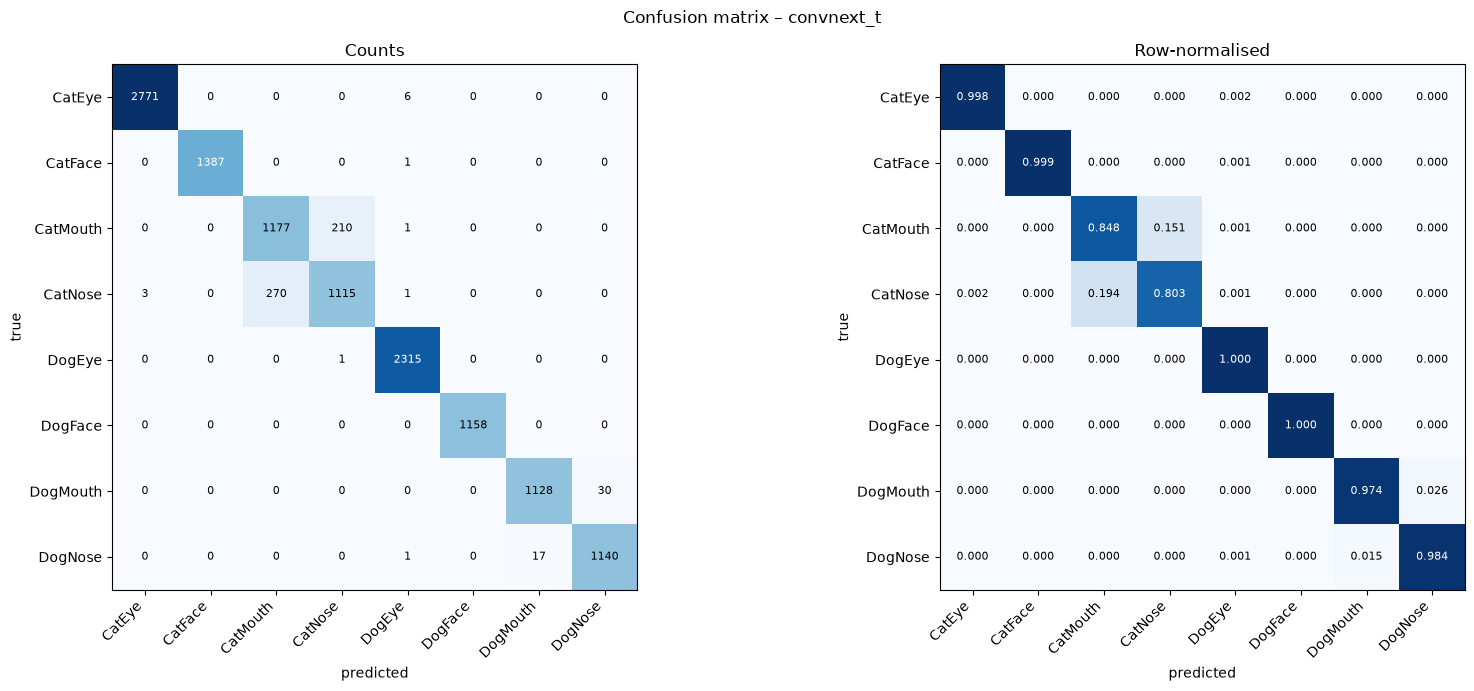

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for a, m, title, fmt in [(axes[0], cm, "Counts", "d"), (axes[1], cm / cm.sum(1, keepdims=True), "Row-normalised", ".3f")]:
    a.imshow(m, cmap="Blues")
    a.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
    a.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            a.text(j, i, format(m[i, j], fmt), ha="center", va="center", fontsize=8,
                   color="white" if m[i, j] > m.max() / 2 else "black")
    a.set_xlabel("predicted")
    a.set_ylabel("true")
    a.set_title(title)
plt.suptitle(f"Confusion matrix – {RUN_NAME}")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion.png", dpi=150)
plt.show()

## 8. Task 6 – Error analysis

In [23]:
pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j]]
pairs = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
species_err = sum(c for t, p, c in pairs.values if t[:3] != p[:3] and t[3:] == p[3:])
feature_err = sum(c for t, p, c in pairs.values if t[3:] != p[3:])
print(f"total errors {cm.sum() - cm.trace()} | same feature, wrong species: {species_err} | wrong feature: {feature_err}")
pairs.head(10)

total errors 541 | same feature, wrong species: 6 | wrong feature: 535


,true,predicted,count
5,CatNose,CatMouth,270
2,CatMouth,CatNose,210
8,DogMouth,DogNose,30
10,DogNose,DogMouth,17
0,CatEye,DogEye,6
4,CatNose,CatEye,3
1,CatFace,DogEye,1
6,CatNose,DogEye,1
3,CatMouth,DogEye,1
7,DogEye,CatNose,1


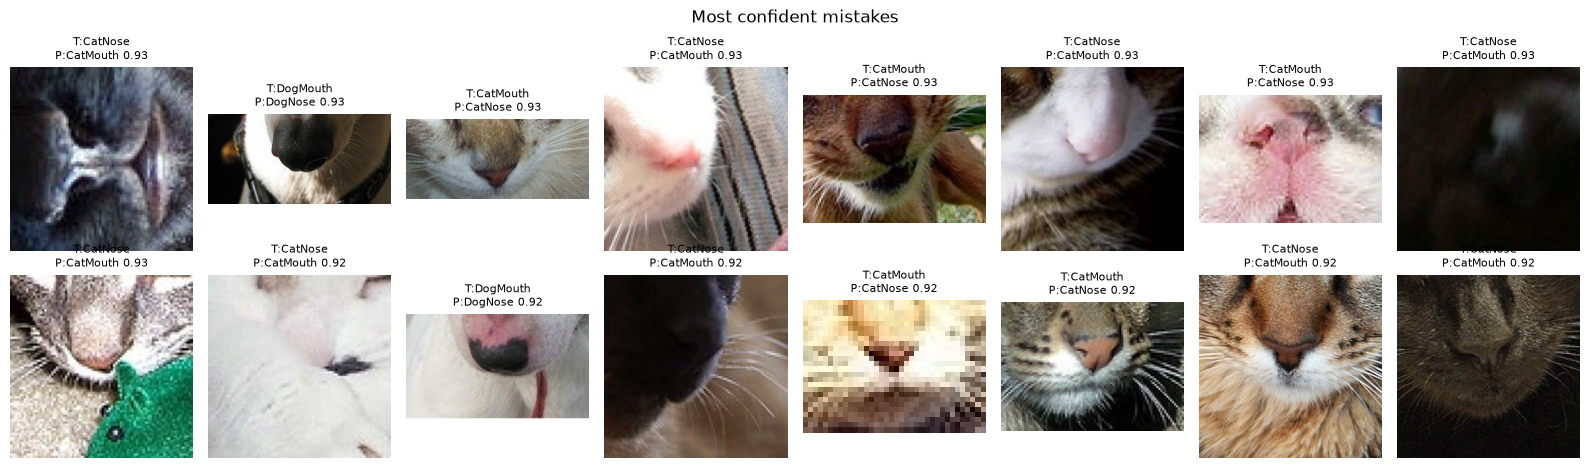

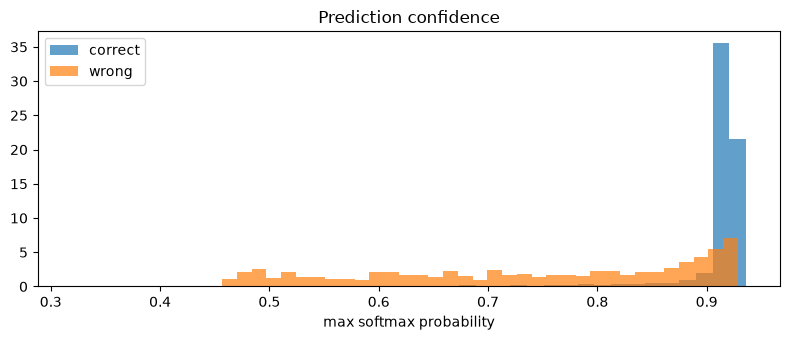

blur score, median – correct: 138.7 | wrong: 97.0


In [24]:
va_res = oof.assign(pred=[CLASSES[i] for i in y_pred], conf=P.max(1))
wrong = va_res[va_res["class"] != va_res["pred"]].sort_values("conf", ascending=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for a in axes.flat:
    a.axis("off")
for a, (_, r) in zip(axes.flat, wrong.head(16).iterrows()):
    a.imshow(Image.open(r["path"]).convert("RGB"))
    a.set_title(f"T:{r['class']}\nP:{r['pred']} {r['conf']:.2f}", fontsize=8)
plt.suptitle("Most confident mistakes")
plt.tight_layout()
plt.savefig(OUT_DIR / "mistakes.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(va_res.loc[va_res["class"] == va_res["pred"], "conf"], bins=40, alpha=0.7, label="correct", density=True)
ax.hist(wrong["conf"], bins=40, alpha=0.7, label="wrong", density=True)
ax.set_xlabel("max softmax probability")
ax.legend()
ax.set_title("Prediction confidence")
plt.tight_layout()
plt.savefig(OUT_DIR / "confidence.png", dpi=150)
plt.show()

print("blur score, median – correct:", round(va_res.loc[va_res["class"] == va_res["pred"], "blur"].astype(float).median(), 1),
      "| wrong:", round(wrong["blur"].astype(float).median(), 1))

### Focus classes
Set `FOCUS` to the classes that perform worst. For each one: what it gets mistaken for, how its image sizes and blur compare between correct and wrong predictions, and example mistakes next to correctly classified images.


CatNose: 274 wrong of 1389 (19.73%)
  predicted as: {'CatMouth': 270, 'CatEye': 3, 'DogEye': 1}
  median pixels  correct 4356 | wrong 5626
  median blur    correct 61 | wrong 99
  also: 211 images of other classes predicted as CatNose: {'CatMouth': 210, 'DogEye': 1}


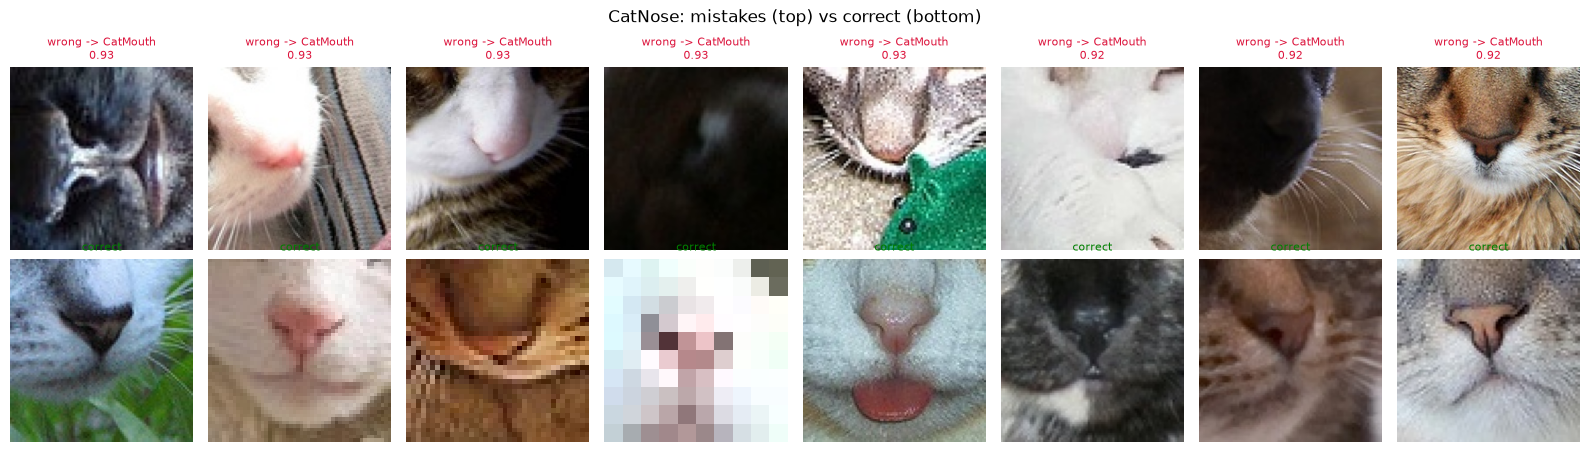


CatMouth: 211 wrong of 1388 (15.20%)
  predicted as: {'CatNose': 210, 'DogEye': 1}
  median pixels  correct 9912 | wrong 5760
  median blur    correct 224 | wrong 106
  also: 270 images of other classes predicted as CatMouth: {'CatNose': 270}


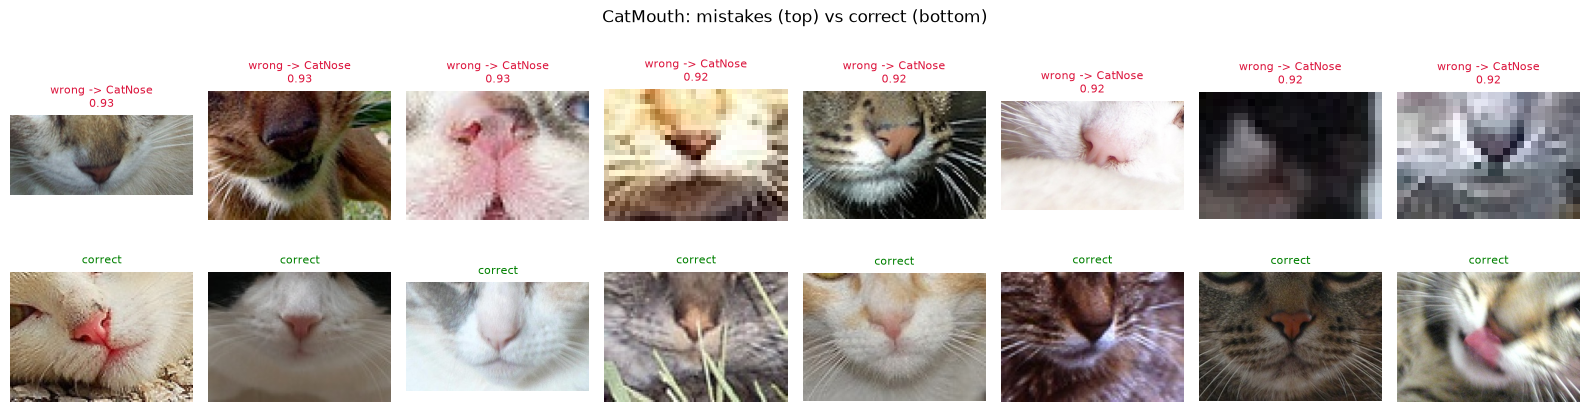

In [25]:
FOCUS = ["CatNose", "CatMouth"]

for c in FOCUS:
    sub_c = va_res[va_res["class"] == c].copy()
    sub_c["px"] = [Image.open(p).size[0] * Image.open(p).size[1] for p in sub_c["path"]]
    ok_c, bad_c = sub_c[sub_c["pred"] == c], sub_c[sub_c["pred"] != c]
    print(f"\n{c}: {len(bad_c)} wrong of {len(sub_c)} ({100 * len(bad_c) / max(1, len(sub_c)):.2f}%)")
    print("  predicted as:", bad_c["pred"].value_counts().to_dict())
    print(f"  median pixels  correct {ok_c['px'].median():.0f} | wrong {bad_c['px'].median():.0f}")
    print(f"  median blur    correct {ok_c['blur'].astype(float).median():.0f} | wrong {bad_c['blur'].astype(float).median():.0f}")
    print(f"  also: {(va_res['pred'] == c).sum() - len(ok_c)} images of other classes predicted as {c}:",
          va_res[(va_res['pred'] == c) & (va_res['class'] != c)]['class'].value_counts().to_dict())

    fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
    for a in axes.flat:
        a.axis("off")
    for a, (_, r) in zip(axes[0], bad_c.sort_values("conf", ascending=False).head(8).iterrows()):
        a.imshow(Image.open(r["path"]).convert("RGB"))
        a.set_title(f"wrong -> {r['pred']}\n{r['conf']:.2f}", fontsize=8, color="crimson")
    for a, (_, r) in zip(axes[1], ok_c.sample(min(8, len(ok_c)), random_state=SEED).iterrows()):
        a.imshow(Image.open(r["path"]).convert("RGB"))
        a.set_title("correct", fontsize=8, color="green")
    plt.suptitle(f"{c}: mistakes (top) vs correct (bottom)")
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"focus_{c}.png", dpi=120)
    plt.show()

## 9. Label-noise check (confident learning)
Images where the out-of-fold model gives the **given** label under 5% probability while being over 95% sure of another class are likely mislabelled. They are listed in `suspect_labels.csv` and shown below.

Review the grid before acting on it. To retrain without them, set `SUSPECT_FILE` in section 1.5 to this run's file and run a new `RUN_NAME`. Note that removing images from the data also makes the validation folds easier, so validation scores before and after are not directly comparable; the Kaggle score is the fair comparison.

0 suspected label errors (0.00% of evaluated images) -> runs\convnext_t\suspect_labels.csv
Series([], dtype: int64)


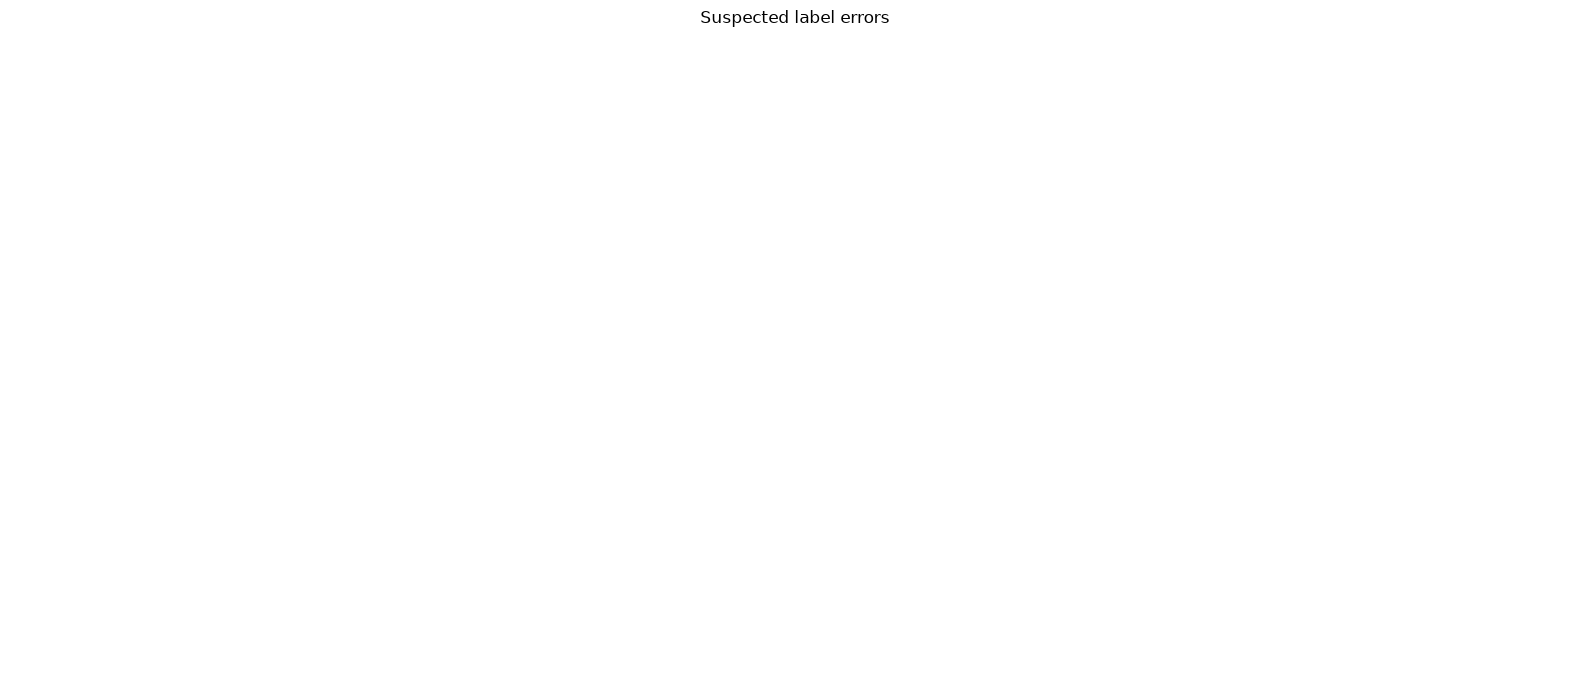

In [26]:
p_given = P[np.arange(len(P)), y_true]
suspect = va_res.assign(p_given=p_given)
suspect = suspect[(suspect["p_given"] < 0.05) & (suspect["conf"] > 0.95)].sort_values("p_given")
suspect[["image_id", "class", "pred", "p_given", "conf"]].to_csv(OUT_DIR / "suspect_labels.csv", index=False)
print(f"{len(suspect)} suspected label errors ({100 * len(suspect) / len(oof):.2f}% of evaluated images) -> {OUT_DIR / 'suspect_labels.csv'}")
print(suspect.groupby(["class", "pred"]).size().sort_values(ascending=False).head(10))

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
for a in axes.flat:
    a.axis("off")
for a, (_, r) in zip(axes.flat, suspect.head(24).iterrows()):
    a.imshow(Image.open(r["path"]).convert("RGB"))
    a.set_title(f"{r['image_id']} label:{r['class']}\nmodel:{r['pred']} {r['conf']:.2f}", fontsize=7)
plt.suptitle("Suspected label errors")
plt.tight_layout()
plt.savefig(OUT_DIR / "suspect_labels.png", dpi=120)
plt.show()

## 10. Log the experiment

In [27]:
row = dict(run=RUN_NAME, model=MODEL_NAME, pretrained=PRETRAINED, augment=AUGMENT, folds=len(results),
           img_size=IMG_SIZE, ft_epochs=FT_EPOCHS, mix_prob=MIX_PROB, ema=EMA_DECAY, lr=LR, batch=BATCH_SIZE,
           params_M=round(n_params / 1e6, 1), val_acc=round(val_acc, 4), val_acc_std=round(float(np.std(fold_accs)), 4),
           val_loss=round(val_loss, 4), macro_f1=round(macro_f1, 4), suspects=len(suspect),
           data_size=len(data), train_min=round(train_time, 1), kaggle_public=None)
json.dump(row, open(OUT_DIR / "metrics.json", "w"), indent=2)

EXP_CSV = RUNS / "experiments.csv"
exp = pd.read_csv(EXP_CSV) if EXP_CSV.exists() else pd.DataFrame()
if len(exp):
    exp = exp[exp["run"] != RUN_NAME]
exp = pd.concat([exp, pd.DataFrame([row])], ignore_index=True)
exp.to_csv(EXP_CSV, index=False)
exp

,run,model,pretrained,augment,img_size,lr,batch,epochs_run,best_epoch,params_M,...,macro_f1,train_min,kaggle_public,folds,ft_epochs,mix_prob,ema,val_acc_std,suspects,data_size
0,convnext_t,convnext_tiny.fb_in22k_ft_in1k,True,strong,224,0.0004,128,NaN,NaN,27.8,...,0.9508,27.8,None,1.0,0.0,0.0,0.999,0.0,0.0,63660.0


## 11. Write and check the submission
Test probabilities are the average over every fold model trained in this run (with TTA). IDs are copied from `sample_submission.csv` so the format matches Kaggle's exactly.

In [28]:
def write_submission(prob, path):
    sub = sample[["image_id"]].copy()
    sub["class"] = [CLASSES[i] for i in prob.argmax(1)]
    assert len(sub) == len(sample)
    assert sub["image_id"].equals(sample["image_id"])
    assert set(sub["class"]) <= set(CLASSES)
    sub.to_csv(path, index=False)
    print(f"{len(sub)} rows -> {path}")
    return sub

sub = write_submission(test_probs, OUT_DIR / "submission.csv")
print(sub.head())
pd.DataFrame({"test predicted %": sub["class"].value_counts(normalize=True) * 100,
              "train %": data["class"].value_counts(normalize=True) * 100}).reindex(CLASSES).round(2)

29443 rows -> runs\convnext_t\submission.csv
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


,test predicted %,train %
class,,
CatEye,21.47,21.81
CatFace,10.56,10.90
CatMouth,10.88,10.90
CatNose,9.88,10.90
DogEye,19.02,18.19
DogFace,9.56,9.10
DogMouth,9.20,9.10
DogNose,9.43,9.10


## 12. Kaggle submission
Either upload `runs/<RUN_NAME>/submission.csv` on the competition page, or use the Kaggle CLI (`pip install kaggle`, API token saved to `%USERPROFILE%\.kaggle\kaggle.json`). Set `COMPETITION` to the slug in the competition URL. Screenshot the leaderboard for the report.

In [29]:
COMPETITION = "your-competition-slug"
!kaggle competitions submit -c {COMPETITION} -f runs/{RUN_NAME}/submission.csv -m "{RUN_NAME} val_acc={val_acc:.4f}"
!kaggle competitions submissions -c {COMPETITION}

'kaggle' is not recognized as an internal or external command,
operable program or batch file.
'kaggle' is not recognized as an internal or external command,
operable program or batch file.


## 13. Task 6 – Compare experiments
Enter the public leaderboard score for each submitted run, then compare against validation.

,run,model,pretrained,augment,img_size,lr,batch,epochs_run,best_epoch,params_M,...,train_min,kaggle_public,folds,ft_epochs,mix_prob,ema,val_acc_std,suspects,data_size,val_minus_kaggle
0,convnext_t,convnext_tiny.fb_in22k_ft_in1k,True,strong,224,0.0004,128,NaN,NaN,27.8,...,27.8,NaN,1.0,0.0,0.0,0.999,0.0,0.0,63660.0,NaN


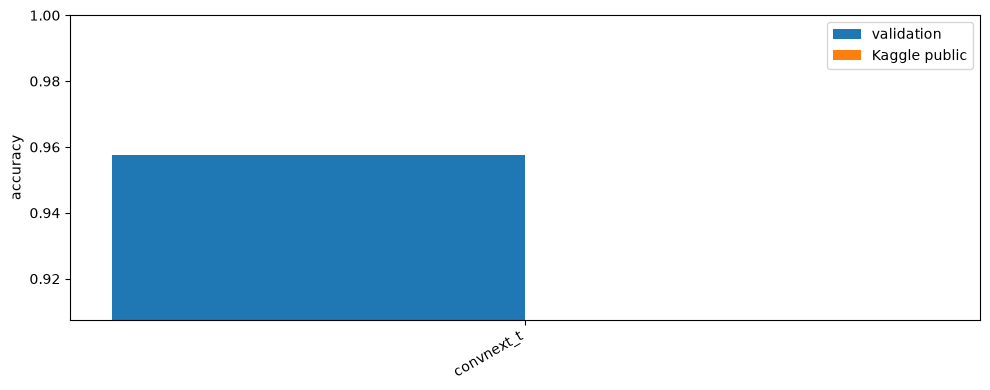

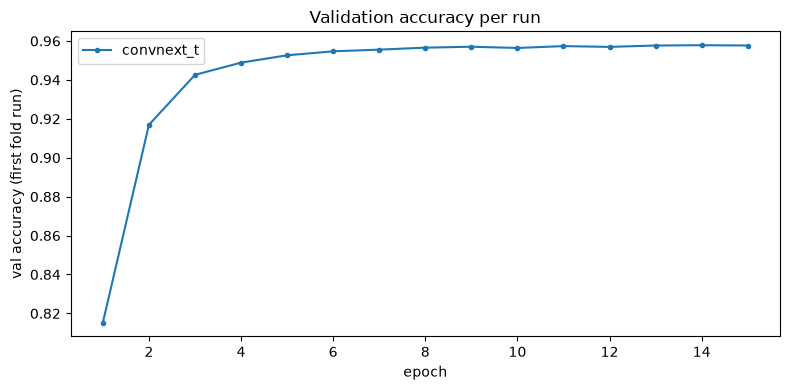

In [30]:
KAGGLE_SCORES = {
    "convnext_t": None,
}

exp = pd.read_csv(RUNS / "experiments.csv")
exp["kaggle_public"] = exp["run"].map(KAGGLE_SCORES).fillna(exp["kaggle_public"])
exp.to_csv(RUNS / "experiments.csv", index=False)
exp["val_minus_kaggle"] = exp["val_acc"] - exp["kaggle_public"]
display(exp.sort_values("val_acc", ascending=False))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(exp))
ax.bar(x - 0.2, exp["val_acc"], 0.4, label="validation")
ax.bar(x + 0.2, exp["kaggle_public"].fillna(0), 0.4, label="Kaggle public")
ax.set_xticks(x, exp["run"], rotation=30, ha="right")
ax.set_ylim(max(0, exp["val_acc"].min() - 0.05), 1)
ax.set_ylabel("accuracy")
ax.legend()
plt.tight_layout()
plt.savefig(RUNS / "experiment_comparison.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for r in exp["run"]:
    f = RUNS / r / "history.csv"
    if f.exists():
        hh = pd.read_csv(f)
        hh = hh[hh["fold"] == hh["fold"].min()]
        ax.plot(hh["epoch"], hh["val_acc"], "o-", label=r, ms=3)
ax.set_xlabel("epoch")
ax.set_ylabel("val accuracy (first fold run)")
ax.legend()
ax.set_title("Validation accuracy per run")
plt.tight_layout()
plt.savefig(RUNS / "val_curves_all.png", dpi=150)
plt.show()

### Ensemble
Averages probabilities from several runs. Out-of-fold predictions are matched by `image_id`, so the ensemble is scored on the images every listed run has a prediction for before submitting.

In [31]:
ENSEMBLE = ["convnext_t", "convnextv2_t"]

oofs = [pd.read_csv(RUNS / r / "oof.csv", dtype={"image_id": str}).set_index("image_id") for r in ENSEMBLE]
common = sorted(set.intersection(*[set(o.index) for o in oofs]))
yt = oofs[0].loc[common, "y"].to_numpy()
for r, o in zip(ENSEMBLE, oofs):
    print(f"{r:20s} val acc {(o.loc[common, CLASSES].to_numpy().argmax(1) == yt).mean():.4f}")
ens_val = np.mean([o.loc[common, CLASSES].to_numpy() for o in oofs], axis=0)
print(f"{'ensemble':20s} val acc {(ens_val.argmax(1) == yt).mean():.4f}  ({len(common)} shared images)")

ens_test = np.mean([np.load(RUNS / r / "test_probs.npy") for r in ENSEMBLE], axis=0)
write_submission(ens_test, RUNS / "submission_ensemble.csv");

FileNotFoundError: [Errno 2] No such file or directory: 'runs\\convnextv2_t\\oof.csv'

## References
- Paszke et al. (2019). PyTorch: An imperative style, high-performance deep learning library. *NeurIPS*. https://pytorch.org
- Wightman, R. (2019). PyTorch Image Models (timm). https://github.com/huggingface/pytorch-image-models
- Pedregosa et al. (2011). Scikit-learn: Machine learning in Python. *JMLR* 12, 2825–2830.
- Liu et al. (2022). A ConvNet for the 2020s (ConvNeXt). *CVPR*. https://arxiv.org/abs/2201.03545
- Woo et al. (2023). ConvNeXt V2: Co-designing and scaling ConvNets with masked autoencoders. *CVPR*. https://arxiv.org/abs/2301.00808
- Dosovitskiy et al. (2021). An image is worth 16x16 words (ViT). *ICLR*. https://arxiv.org/abs/2010.11929
- He et al. (2016). Deep residual learning for image recognition (ResNet). *CVPR*. https://arxiv.org/abs/1512.03385
- Loshchilov & Hutter (2019). Decoupled weight decay regularization (AdamW). *ICLR*. https://arxiv.org/abs/1711.05101
- Loshchilov & Hutter (2017). SGDR: Stochastic gradient descent with warm restarts (cosine schedule). *ICLR*. https://arxiv.org/abs/1608.03983
- Cubuk et al. (2020). RandAugment. *CVPR Workshops*. https://arxiv.org/abs/1909.13719
- Zhong et al. (2020). Random erasing data augmentation. *AAAI*. https://arxiv.org/abs/1708.04896
- Zhang et al. (2018). mixup: Beyond empirical risk minimization. *ICLR*. https://arxiv.org/abs/1710.09412
- Yun et al. (2019). CutMix: Regularization strategy to train strong classifiers. *ICCV*. https://arxiv.org/abs/1905.04899
- Szegedy et al. (2016). Rethinking the Inception architecture (label smoothing). *CVPR*. https://arxiv.org/abs/1512.00567
- Huang et al. (2016). Deep networks with stochastic depth (drop path). *ECCV*. https://arxiv.org/abs/1603.09382
- Polyak & Juditsky (1992). Acceleration of stochastic approximation by averaging (weight averaging / EMA). *SIAM J. Control Optim.* 30(4).
- Touvron et al. (2019). Fixing the train-test resolution discrepancy (higher-resolution fine-tuning). *NeurIPS*. https://arxiv.org/abs/1906.06423
- Northcutt et al. (2021). Confident learning: Estimating uncertainty in dataset labels. *JAIR* 70. https://arxiv.org/abs/1911.00068